# Fleet Safety Priorities in Great Britain, 2024–2025
## Business context and sources
I'm advising a hypothetical fleet-safety consultancy on training drivers and reviewing operations, using STATS19 records of police-reported injury collisions in Great Britain.

Scope: collisions with types 19/20/21/98 (vans/goods vehicles including unknown weight) have been counted once; all casualties in these collisions have been included. Type is not an indicator of ownership or the purpose of the journey; involvement does not connote fault. The vehicle records cannot identify the same vehicle across different crashes. Without mileage/journey data, counts cannot determine travel risk.

This portfolio copy uses the six-CSV snapshot recorded on 14 September 2026 (DfT, 2026b). The analysis uses pandas, NumPy, Matplotlib and openpyxl. Run from the repository root after following the README data instructions.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT = Path.cwd()
if not (PROJECT / "datasets").is_dir():
    PROJECT = PROJECT / "Project"
DATA, DOCS = PROJECT / "datasets", PROJECT / "supporting_docs"
assert DATA.is_dir() and DOCS.is_dir(), "Project data folders not found"
YEAR, ID = "collision_year", "collision_index"
tables = {}
keys = {"collision": [ID], "vehicle": [ID, "vehicle_reference"],
        "casualty": [ID, "casualty_reference"]}
for name in keys:
    yearly = []
    for year in (2024, 2025):
        frame = pd.read_csv(DATA / f"dft-road-casualty-statistics-{name}-{year}.csv",
            dtype={ID: "string", "collision_ref_no": "string"},
            low_memory=False)
        assert frame[YEAR].eq(year).all(), "Unexpected year"
        yearly.append(frame)
    assert yearly[0].columns.equals(yearly[1].columns), name
    tables[name] = pd.concat(yearly, ignore_index=True)

c, v, k = (tables[n] for n in keys)
audit = {}
for name, frame in tables.items():
    assert not frame[keys[name]].isna().any().any(), name
    assert not frame.duplicated(keys[name]).any(), name
    assert frame[ID].isin(c[ID]).all(), name
    audit[name] = {2024: frame[YEAR].eq(2024).sum(),
            2025: frame[YEAR].eq(2025).sum(),
            "Columns": len(frame.columns), "Blank cells": frame.isna().sum().sum()}
    # Linked year/reference metadata must agree, not merely the join key.
    link = frame.merge(c[[ID, YEAR, "collision_ref_no"]], on=ID,
            validate="many_to_one", suffixes=("", "_parent"))
    for field in (YEAR, "collision_ref_no"):
        assert link[field].eq(link[field + "_parent"]).all(), field
for frame, field in [(v, "number_of_vehicles"), (k, "number_of_casualties")]:
    observed = frame.groupby(ID).size().reindex(c[ID], fill_value=0)
    assert observed.eq(c.set_index(ID)[field]).all(), field
link = k.merge(v[[ID, "vehicle_reference"]], on=[ID, "vehicle_reference"],
            how="left", validate="many_to_one", indicator=True)
assert link["_merge"].eq("both").all(), "Unmatched casualty vehicle"
display(pd.DataFrame(audit).T)

,2024,2025,Columns,Blank cells
collision,100927,101525,44,8
vehicle,183514,183948,32,0
casualty,128272,127883,23,0


Raw totals: 202,452 collisions, 367,462 vehicle records, 256,155 casualties. Keys are complete and unique; the per-collision vehicle and casualty totals match with the linked metadata. The eight blanks are unused coordinates in two retained collisions.

Even though the headers match, their meanings still have to be checked; weather is mislabeled as surface values by the conversion sheet. I use `2024_code_list`, confirmed by STATS20 §1.22 (DfT, 2025). Motorcycle revisions remain in the same group and there is no type 33. Some detail of specification is hidden within broad groups. The local DOCX guides are undated and partly historical.

## Preparation
Membership selection avoids duplicate collisions. Dates are explicitly parsed; exclusions are field-specific (code 9 means car for vehicle type but unknown for weather). Setting 3 is unallocated. Joins, grouping and reshaping are based on McKinney (2022, chs 8 and 10).

In [2]:
guide = pd.read_excel(DOCS / "dft-road-casualty-statistics-road-safety-open-dataset-data-guide-2025.xlsx", sheet_name="2024_code_list")
goods = v.loc[v.vehicle_type.isin([19, 20, 21, 98])]
fleet = c.loc[c[ID].isin(goods[ID])].copy()
cas = k.merge(fleet[[ID]], on=ID, validate="many_to_one")
assert len(cas) == fleet.number_of_casualties.sum()
fleet["date"] = pd.to_datetime(fleet.date, format="%d/%m/%Y", errors="raise")
time = pd.to_datetime(fleet.time, format="%H:%M", errors="raise")
assert fleet.date.notna().all() and time.notna().all()
assert fleet.date.dt.year.eq(fleet[YEAR]).all()
assert ((fleet.date.dt.dayofweek + 1) % 7 + 1).eq(fleet.day_of_week).all()
fleet["hour"], fleet["weekday"] = time.dt.hour, fleet.date.dt.day_name()
unknown = {"speed_limit": [-1, 99], "light_conditions": [-1],
           "weather_conditions": [-1, 9], "urban_or_rural_area": [-1]}
for field, values in unknown.items():
    fleet[field] = fleet[field].mask(fleet[field].isin(values))
fleet["Setting"] = fleet.urban_or_rural_area.map({1: "Urban", 2: "Rural"})
assert fleet.urban_or_rural_area.dropna().isin([1, 2, 3]).all()
scope = pd.DataFrame({"Collisions": fleet.groupby(YEAR).size(),
            "Goods records": goods.groupby(YEAR).size(),
            "Casualties": cas.groupby(YEAR).size(),
            "Weather unknown": fleet.weather_conditions.isna().groupby(fleet[YEAR]).sum()})
display(scope)

def severity(frame, prefix):
    """Give fatalities weight 1 and other records their serious probability."""
    observed = frame[prefix + "_severity"]
    serious = frame[prefix + "_adjusted_severity_serious"]
    slight = frame[prefix + "_adjusted_severity_slight"]
    nonfatal = observed.ne(1)
    assert observed.isin([1, 2, 3]).all()
    assert serious[nonfatal].between(0, 1).all()
    assert slight[nonfatal].between(0, 1).all()
    assert np.allclose((serious + slight)[nonfatal], 1)
    frame["weight"] = np.where(observed.eq(1), 1., serious)
    frame["recorded"] = observed.isin([1, 2])

severity(fleet, "collision")
severity(cas, "casualty")

def summary(frame, groups):
    result = frame.groupby(groups).agg(n=(ID, "size"),
            Adjusted=("weight", "sum"))
    result["Adjusted_pct"] = 100 * result.Adjusted / result.n
    assert result.n.sum() == len(frame), "Grouping lost records"
    assert np.isclose(result.Adjusted.sum(), frame.weight.sum())
    return result

def year_check(frame, groups):
    pooled = summary(frame, groups)
    annual = summary(frame, [YEAR] + groups).Adjusted_pct.unstack(YEAR)
    return pooled[["n", "Adjusted_pct"]].join(annual).round(2)

plt.rcParams.update({"font.size": 10, "figure.dpi": 110,
            "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE = "#2878A0", "#C76A17"

,Collisions,Goods records,Casualties,Weather unknown
collision_year,,,,
2024,13992,15215,18385,284
2025,15410,16745,20048,243


The collisions and casualties in the subset are 29,402 and 38,433, respectively. For eligible collisions in 2024 and 2025, weather is unknown for 2.03% and 1.58%, respectively; this missingness could be systematic. Three lighting values are unknown and two road settings are unallocated. Dates/times/weekday codes validate.

Severity: fatal records have weight 1; non-fatal records receive the published serious probability (DfT, 2026a; 2026b). The code works separately for collision and casualty records, referring to the respective `_adjusted_severity_serious` columns. Probability checks are completed before aggregating the resultant statistics. Thus, totals can be fractional. KSI stands for killed or seriously injured: Q1/Q5 use casualty denominators; Q2–Q4 and Q6 use collision denominators. The calculation of "adjusted severe %" is the estimated number of fatal-or-serious collisions per 100 group collisions.

Annual checks test pooling. No significance is claimed; binomial intervals would omit adjustment-model uncertainty and casualty clustering.

## Business analysis
### 1. How did casualty burden and severity change?
Annual aggregation and percentage change distinguish workload growth from severity composition.

In [3]:
annual = summary(cas, YEAR).rename(columns={"n": "Casualties", "Adjusted": "Adjusted_KSI"})
annual["Recorded_KSI"] = cas.groupby(YEAR).recorded.sum()
annual["IBRS_pct"] = cas.groupby(YEAR).casualty_injury_based.mean() * 100
display(annual.round(2))
print("Change (%):", annual[["Casualties", "Adjusted_KSI"]]
      .pct_change().iloc[-1].mul(100).round(2).to_dict())

,Casualties,Adjusted_KSI,Adjusted_pct,Recorded_KSI,IBRS_pct
collision_year,,,,,
2024,18385,4021.06,21.87,3859,77.65
2025,20048,4393.88,21.92,4317,87.30


Change (%): {'Casualties': 9.05, 'Adjusted_KSI': 9.27}


Casualties rose 9.0% (18,385→20,048); adjusted KSI rose 9.3% (4,021.06→4,393.88). Its share barely changed (21.87%→21.92%). The proportion of casualties recorded by injury-based reporting systems (IBRS) increased from 77.65% to 87.30%; this reinforced the need for severity adjustment when comparing years. Before making an inference of worsening travel safety, investigate exposure.

### 2. Which hours and weekdays have the most collisions?
The grouping and chronological reindexing feature determines review periods and the annual check tests pooled peaks.

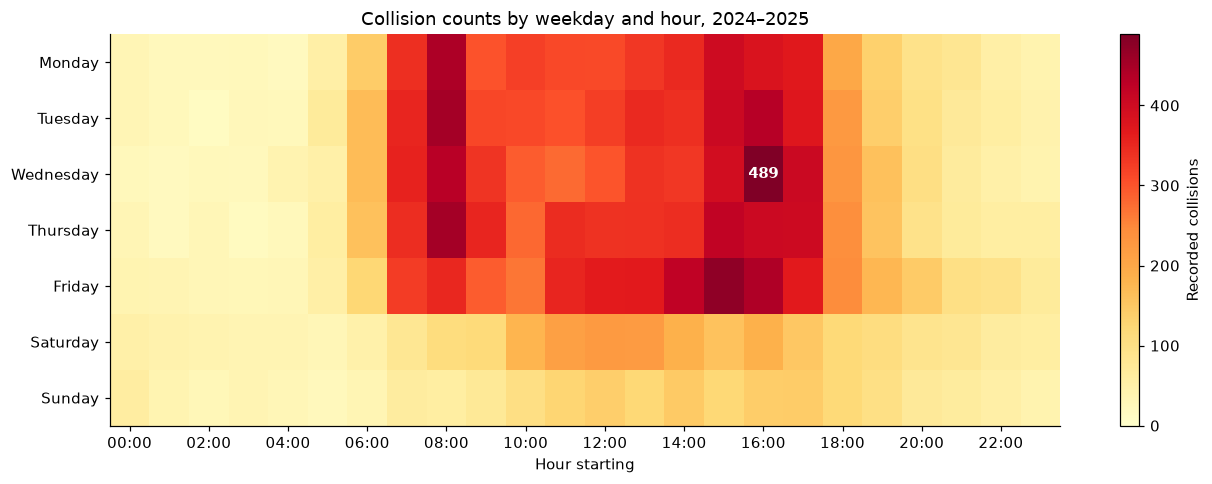

2024 — highest-count weekday/hour combinations:
weekday    hour
Wednesday  16      229
Friday     16      228
dtype: int64
Adjusted severe weekday/weekend: 24.94%/29.22%
2025 — highest-count weekday/hour combinations:
weekday    hour
Wednesday  16      260
Friday     15      254
dtype: int64
Adjusted severe weekday/weekend: 25.17%/26.82%


In [4]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
joint = fleet.groupby(["weekday", "hour"]).size().unstack(fill_value=0)
joint = joint.reindex(index=days, columns=range(24), fill_value=0)
assert joint.to_numpy().sum() == len(fleet)

fig, ax = plt.subplots(figsize=(12, 4.5))
im = ax.imshow(joint, aspect="auto", cmap="YlOrRd", vmin=0)
row, col = np.unravel_index(joint.to_numpy().argmax(), joint.shape)
ax.text(col, row, str(joint.iloc[row, col]), ha="center", va="center",
        color="white", fontsize=10, fontweight="bold")
ax.set_yticks(range(7), days)
ax.set_xticks(range(0, 24, 2), [f"{h:02d}:00" for h in range(0, 24, 2)])
ax.set(xlabel="Hour starting", title="Collision counts by weekday and hour, 2024–2025")
fig.colorbar(im, ax=ax, label="Recorded collisions")
fig.tight_layout()
plt.show()

for year, group in fleet.groupby(YEAR):
    print(year, "— highest-count weekday/hour combinations:")
    print(group.groupby(["weekday", "hour"]).size().nlargest(2))
    rates = group.groupby(group.weekday.isin(days[-2:])).weight.mean() * 100
    print(f"Adjusted severe weekday/weekend: {rates[False]:.2f}%/{rates[True]:.2f}%")

Wednesday 16:00–16:59 leads overall (489) and in both years (229; 260), but Friday 16:00 is nearly tied in 2024 (228). Morning and afternoon operations shall be reviewed against client mileage; counts cannot determine journey risk. The weekend–weekday severity gap falls from 4.28 to 1.65 percentage points.

### 3. Which local authorities have the greatest collision burden?
Mapping ONS codes to area names, ranking collision counts and comparing annual leaders identifies areas for review.

Initially unlabelled collisions: 112


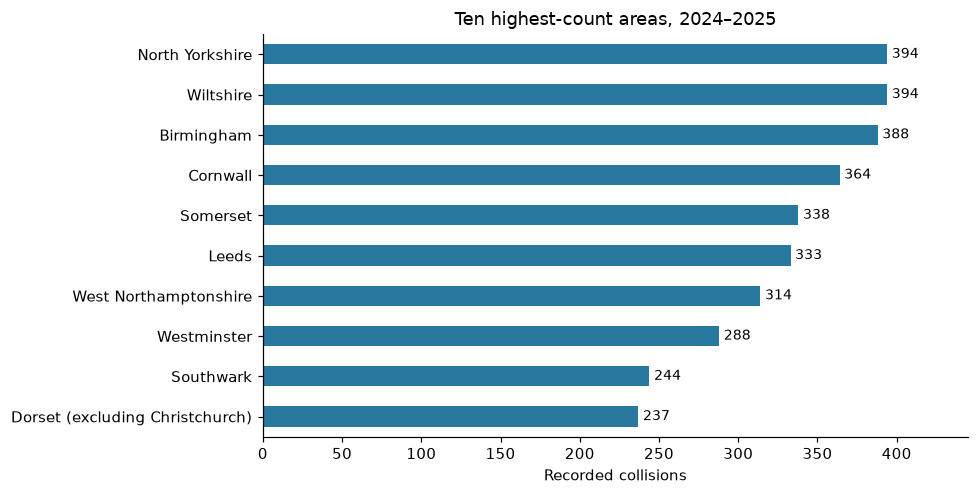

Top-ten share: 11.2%
2024 {'Birmingham': 175, 'Leeds': 171, 'Somerset': 164}
2025 {'North Yorkshire': 244, 'Wiltshire': 241, 'Cornwall': 216}


In [5]:
area_field = "local_authority_ons_district"
lookup = guide.loc[guide["field name"].eq(area_field), ["code/format", "label"]].drop_duplicates()
lookup = lookup.set_index("code/format").label
assert lookup.index.is_unique
codes = fleet[area_field].astype("string").str.strip()
print("Initially unlabelled collisions:", codes.map(lookup).isna().sum())
for value, label in {"E08000016": "Barnsley", "E08000038": "Barnsley",
            "E08000019": "Sheffield", "E08000039": "Sheffield"}.items():
    lookup.loc[value] = label
fleet["Area"] = codes.map(lookup)
assert fleet.Area.notna().all()
areas = summary(fleet, "Area")
top = areas.nlargest(10, "n").sort_values("n")
ax = top.n.plot.barh(figsize=(9, 4.6), color=BLUE)
ax.bar_label(ax.containers[0], padding=3, fontsize=9)
ax.set(xlabel="Recorded collisions", ylabel="", xlim=(0, 445),
       title="Ten highest-count areas, 2024–2025")
plt.tight_layout()
plt.show()
print(f"Top-ten share: {100 * top.n.sum() / len(fleet):.1f}%")
for year, group in fleet.groupby(YEAR):
    print(year, group.Area.value_counts().head(3).to_dict())

Barnsley/Sheffield codes E08000038/E08000039 replace E08000016/E08000019 (HM Land Registry, 2025), resolving 112 labels. Combining the names preserves all the records but doesn't harmonise the boundaries.

North Yorkshire/Wiltshire tie at 394; Birmingham comes in a close second (388). Annual leaders differ. Only 11.2% of collisions are in the top ten. The findings are to be compared with client routes and mileage. Differences in area size and road networks prevent safety rankings based on collision counts alone.

### 4. Does there exist a difference in severity between speed limits in urban/rural settings?
When doing route reviews, I remove 2 unallocated settings and categorize by limit/setting. Denominators are provided by labels; annual percentages test pooling.

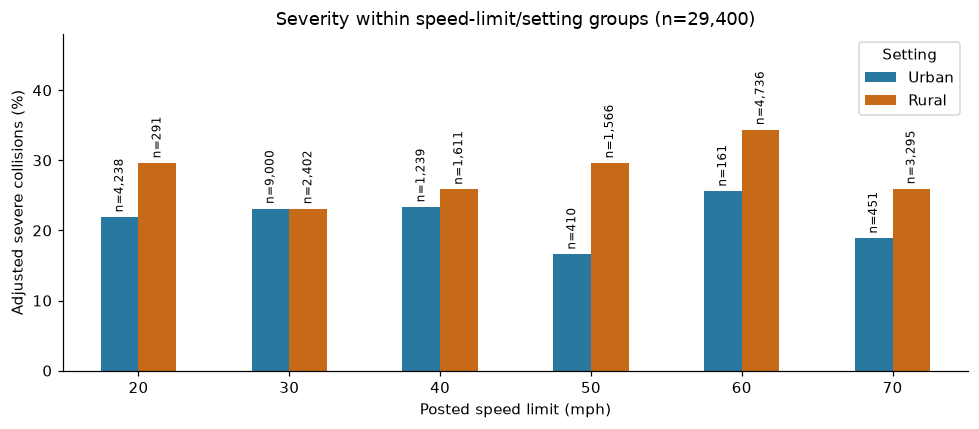

n  Adjusted_pct   2024   2025
speed_limit Setting                                  
20          Rural     291         29.64  31.81  27.97
            Urban    4238         21.92  22.47  21.43
30          Rural    2402         23.09  21.16  24.72
            Urban    9000         23.13  22.84  23.40
40          Rural    1611         25.86  26.25  25.52
            Urban    1239         23.36  22.65  24.05
50          Rural    1566         29.63  31.10  28.31
            Urban     410         16.61  15.82  17.47
60          Rural    4736         34.38  34.64  34.15
            Urban     161         25.60  28.62  22.30
70          Rural    3295         25.94  27.64  24.37
            Urban     451         18.90  17.69  19.84

In [6]:
road = fleet.loc[fleet.Setting.notna() & fleet.speed_limit.notna()].copy()
road["speed_limit"] = road.speed_limit.astype(int)
road_stats = summary(road, ["speed_limit", "Setting"])
rates = road_stats.Adjusted_pct.unstack().reindex(columns=["Urban", "Rural"])
counts = road_stats.n.unstack().reindex(columns=rates.columns)
ax = rates.plot.bar(figsize=(9, 4), color=[BLUE, ORANGE], rot=0)
for container, setting in zip(ax.containers, rates.columns):
    ax.bar_label(container, labels=[f"n={n:,}" for n in counts[setting]],
            fontsize=8, rotation=90, padding=3)
ax.set(xlabel="Posted speed limit (mph)", ylabel="Adjusted severe collisions (%)",
       title=f"Severity within speed-limit/setting groups (n={len(road):,})", ylim=(0, 48))
plt.tight_layout()
plt.show()
display(year_check(road, ["speed_limit", "Setting"]))

Rural roads show the highest severe-collision percentage overall at 60 mph (34.38%; n=4,736) as well as each year, which supports further route review. The rural and urban gap at 50 mph is 13.02 percentage points, while at 30 mph, nearly equal pooled percentages conceal an annual reversal. Severity is not monotonic with limit; limits are not actual speeds. The smallest pooled group contains 161 collisions. Inference is limited due to small cells and different road/vehicle mix.

### 5. Who suffers most in terms of casualties?
A dictionary groups casualty types while retaining unknowns. Driver-awareness priorities are provided by counts, adjusted KSI and annual shares.

,Adjusted,n,Adjusted_pct,2024,2025
Road_user,,,,,
Car/taxi occupants,3127.64,18669,16.75,16.67,16.84
Goods occupants,1536.06,8827,17.40,17.86,16.99
Pedestrians,1381.67,3942,35.05,35.23,34.88
Cyclists,940.21,3219,29.21,29.49,28.97
Motorcyclists,1231.97,2937,41.95,41.26,42.54
Bus/minibus occupants,70.70,437,16.18,14.34,18.18
Other known,70.30,228,30.83,33.81,27.86
Unknown,56.39,174,32.41,33.50,31.13


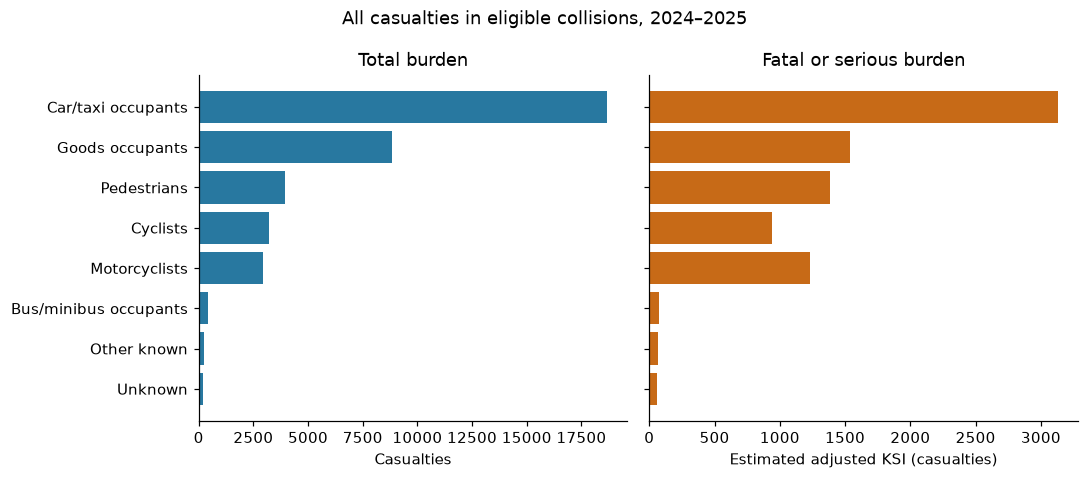

In [7]:
groups = {"Pedestrians": [0], "Cyclists": [1],
          "Motorcyclists": [2, 3, 4, 5, 23, 97], "Car/taxi occupants": [8, 9],
          "Goods occupants": [19, 20, 21, 98], "Bus/minibus occupants": [10, 11],
          "Other known": [16, 17, 18, 22, 90], "Unknown": [-1, 99]}
mapping = {value: label for label, values in groups.items() for value in values}
cas["Road_user"] = cas.casualty_type.map(mapping)
assert cas.Road_user.notna().all(), "Unmapped casualty type"
users = summary(cas, "Road_user").sort_values("n", ascending=False)
display(users[["Adjusted"]].join(year_check(cas, ["Road_user"])).round(2))
fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), sharey=True)
plot = users.sort_values("n")
axes[0].barh(plot.index, plot.n, color=BLUE)
axes[1].barh(plot.index, plot.Adjusted, color=ORANGE)
axes[0].set(xlabel="Casualties", title="Total burden")
axes[1].set(xlabel="Estimated adjusted KSI (casualties)", title="Fatal or serious burden")
fig.suptitle("All casualties in eligible collisions, 2024–2025")
fig.tight_layout()
plt.show()

Car/taxi occupants lead casualties (18,669) and adjusted KSI (3,127.64), with a 16.75% share. Motorcyclists (including passengers), pedestrians and cyclists show higher adjusted KSI shares compared to car/goods occupants: 41.95%, 35.05% and 29.21%, respectively. “Other known” (30.83%) and “Unknown” (32.41%) have higher KSI shares than cyclists, but these are broad and/or unidentified categories and do not support specific training priorities. Since the figures do not establish fault, cases involving car occupants and vulnerable road users must be reviewed before training content is selected.

### 6. Are there any differences in severity when lighting/weather occurs in urban versus rural areas?
Environmental reviews are conducted with group and stratified comparisons. A code of 7 (lighting status unknown) indicates darkness. Fine/rain/snow is a combination of wind categories; exclusions are separate.

Lighting — pooled n and adjusted %, then annual adjusted %:


n  Adjusted_pct   2024   2025
Condition Setting                                   
Darkness  Rural     2929         32.80  32.32  33.27
          Urban     3196         25.28  25.67  24.90
Daylight  Rural    10970         27.73  28.35  27.20
          Urban    12302         21.84  21.61  22.06

Weather — pooled n and adjusted %, then annual adjusted %:


n  Adjusted_pct   2024   2025
Condition Setting                                   
Fine      Rural    11573         29.44  29.81  29.13
          Urban    12744         22.84  22.65  23.01
Fog/mist  Rural       84         37.20  37.53  36.83
          Urban       28         17.94  33.33   6.40
Other     Rural      285         25.27  27.62  23.32
          Urban      546         20.87  21.03  20.74
Rain      Rural     1794         25.59  26.49  24.64
          Urban     1744         22.83  22.38  23.37
Snow      Rural       47         38.53  32.30  42.76
          Urban       28         18.16  17.65  18.94

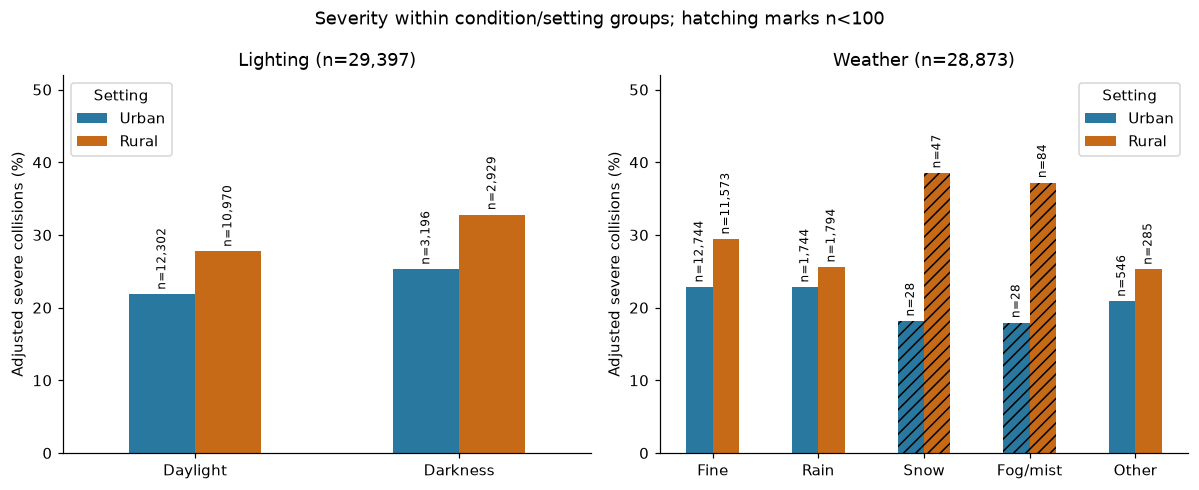

Rural 60 mph: pooled n and adjusted %, then annual %


,n,Adjusted_pct,2024,2025
Lighting,,,,
Darkness,874,38.84,37.31,40.38
Daylight,3861,33.37,33.98,32.85


Weather completeness, before road-setting exclusions:


,n,Adjusted_pct,2024,2025
Weather_status,,,,
Known,28875,25.70,25.75,25.66
Unknown,527,14.95,18.78,10.47


In [8]:
environment = {
    "Lighting": ("light_conditions",
            {1: "Daylight", 4: "Darkness", 5: "Darkness",
            6: "Darkness", 7: "Darkness"}, ["Daylight", "Darkness"]),
    "Weather": ("weather_conditions",
            {1: "Fine", 4: "Fine", 2: "Rain", 5: "Rain", 3: "Snow",
            6: "Snow", 7: "Fog/mist", 8: "Other"},
            ["Fine", "Rain", "Snow", "Fog/mist", "Other"])}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (title, (field, mapping, order)) in zip(axes, environment.items()):
    assert fleet[field].dropna().isin(mapping).all(), field
    selected = fleet.loc[fleet.Setting.notna() & fleet[field].notna()].copy()
    selected["Condition"] = selected[field].map(mapping)
    result = summary(selected, ["Condition", "Setting"])
    rates = result.Adjusted_pct.unstack().reindex(index=order, columns=["Urban", "Rural"])
    rates.plot.bar(ax=ax, color=[BLUE, ORANGE], rot=0)
    for container, setting in zip(ax.containers, rates.columns):
        ns = result.n.unstack().reindex(order)[setting]
        for bar, n in zip(container, ns):
            if n < 100:
                bar.set_hatch("///")
        ax.bar_label(container, labels=[f"n={n:,}" for n in ns], fontsize=8, rotation=90, padding=3)
    ax.set(title=f"{title} (n={len(selected):,})", xlabel="",
           ylabel="Adjusted severe collisions (%)", ylim=(0, 52))
    print(title, "— pooled n and adjusted %, then annual adjusted %:")
    display(year_check(selected, ["Condition", "Setting"]))
fig.suptitle("Severity within condition/setting groups; hatching marks n<100")
fig.tight_layout()
plt.show()

rural60 = fleet.loc[fleet.Setting.eq("Rural") & fleet.speed_limit.eq(60)].copy()
rural60["Lighting"] = rural60.light_conditions.map(environment["Lighting"][1])
print("Rural 60 mph: pooled n and adjusted %, then annual %")
display(year_check(rural60.dropna(subset=["Lighting"]), ["Lighting"]))

missing = fleet.assign(
    Weather_status=np.where(fleet.weather_conditions.isna(), "Unknown", "Known")
)
print("Weather completeness, before road-setting exclusions:")
display(year_check(missing, ["Weather_status"]))

After field-specific exclusions, the number of collisions retained in the lighting category is 29,397 and in the weather category is 28,873. In both years, the severe proportion of darkness is higher than the severe proportion of daylight in rural (32.80% vs 27.73%) and urban (25.28% vs 21.84%) areas.

On rural 60 mph roads, the adjusted severe share is greater in the dark (38.84%, n=874) than it is in the day (33.37%, n=3,861) for both years. One record with unknown lighting is excluded. This facilitates focused review, but daylight brings more collisions and confounding remains.

The adjusted severe share of the unknown-weather records is lower than the adjusted severe share of the known-weather records, before road-setting exclusions (14.95%; n=527) compared to (25.70%; n=28,875). The groups vary in terms of severity observed; this does not validate the absence of weather.

Rural snow's pooled 38.53% spans 32.30% in 2024 (n=19) and 42.76% in 2025 (n=28). The number of collisions for rural fog/mist is 84. Hatching marks are used as a warning for n<100, not as evidence of significance. These findings are not sufficient to conclude that rain is safer or justify a snow-specific priority.

## Conclusions and recommendations
Casualty burden increased with little change in adjusted KSI share. Recommended investigations are:

1. Review afternoon schedules and severe weekend cases against mileage/journeys.
2. Review operations on rural 60 mph roads in darkness in conjunction with client journey data, and acknowledge the larger collision burden during the day.
3. Prior to choosing training content, review car and vulnerable road user interactions.
4. Geographic priorities must be matched to the client's routes and mileage, recognising that most collisions occur outside the 10 highest-count areas.

Strengths are associated with official records, enforced checks, justified coding, adjustment and annual/stratified comparisons. Limits are unreported/damage-only collisions, uncertain commercial use, changing reporting/boundaries, unknowns, broad groups and unquantified uncertainty. Severity adjustment does not remove confounding. Two years are not enough to establish a trend; severity of injury collisions does not measure the collision risk per journey.

Then get mileage/journeys by time, route and vehicle type and internal incidents. Select implementable interventions with the client and compare incidents/exposures to a similar time period/group. No benefit or cost saving has been estimated.

## References
Department for Transport (DfT) (2025) *STATS20: Instructions for the completion of road collision reports*. 2024 specification, updated 29 May, §1.22. Available at: [DfT](https://assets.publishing.service.gov.uk/media/68373908e11dd1e85b0cbb24/STATS20_2024_specification.pdf) (Accessed: 14 September 2026).

Department for Transport (DfT) (2026a) *Guide to severity adjustments for reported road casualties Great Britain*. Updated 30 July. Available at: [GOV.UK](https://www.gov.uk/government/publications/guide-to-severity-adjustments-for-reported-road-casualty-statistics/guide-to-severity-adjustments-for-reported-road-casualties-great-britain) (Accessed: 14 September 2026).

Department for Transport (DfT) (2026b) *Road safety open data*. Updated 30 July. Includes CSVs, data guide and historical/severity DOCX guides; attachment dates are not established by the collection date. Available at: [GOV.UK](https://www.gov.uk/government/statistical-data-sets/road-safety-open-data) (Accessed: 14 September 2026).

HM Land Registry (2025) ‘April 2025 – Changes to local authority geography in England’, *UK House Price Index: Change History*. Available at: [HM Land Registry](https://landregistry.data.gov.uk/app/ukhpi/changelog) (Accessed: 14 September 2026).

McKinney, W. (2022) *Python for Data Analysis: Data Wrangling with pandas, NumPy, and Jupyter*. 3rd edn. O’Reilly Media, chs 8 and 10. Available at: [author's open edition](https://wesmckinney.com/book/) (Accessed: 14 September 2026).